# Graphicalizing a Scene Image

This notebook loads a local village landscape with houses, cars, and people, asks a vision-language model to describe the scene and locate foreground entities, analyzes saved region crops against the visual ontology, and extracts relations across the resulting graph. Install the optional dependency with `pip install -e '.[image]'`. Set `OPENAI_API_KEY` in the environment before running the model cell; the key is read by the OpenAI SDK and is never stored in this notebook.

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Image: office.png


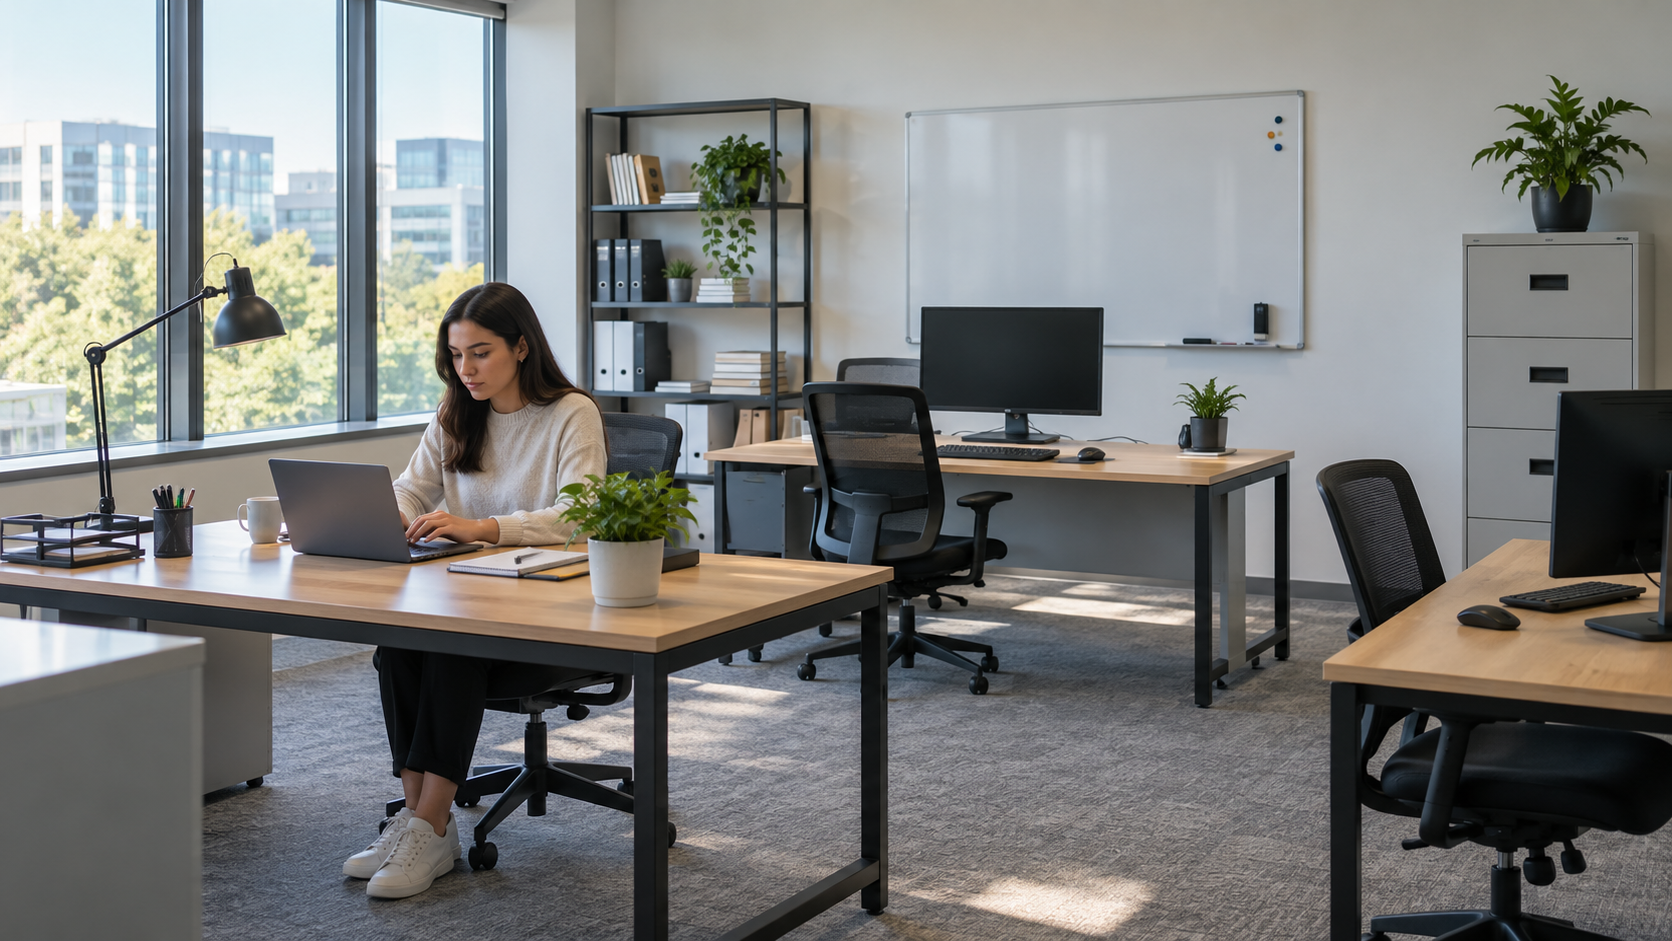

In [24]:
%config InlineBackend.figure_format = 'retina'

%load_ext autoreload
%autoreload 2

from pathlib import Path
from IPython.display import Image as DisplayImage, display

from semantic_graphicalizer import ImageGraphicalizer, display_graph

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
IMAGE_ROOT = ROOT / 'domains' / 'image'

image_path = IMAGE_ROOT / 'data' / 'raw' / 'office_scene.png' # cat landscape office
if not image_path.is_file():
    raise FileNotFoundError(f'Add a local photograph at {image_path}')

print(f'Image: {image_path.name}')
display(DisplayImage(filename=str(image_path), width=900))

## OpenAI vision model

The image workflow defaults to `gpt-5.6-terra` through the Responses API. The workflow has three image-specific stages: whole-image scene inventory, per-crop ontology analysis, and document-level relation extraction. Region crops are saved under `domains/image/data/processed/regions/`.

In [ ]:
graphicalizer = ImageGraphicalizer(
    ontology=IMAGE_ROOT / 'configs' / 'ontologies' / 'visual.yaml',
    prompts=IMAGE_ROOT / 'configs' / 'prompts' / 'scene_analysis.yaml',
    crop_dir=IMAGE_ROOT / 'data' / 'processed' / 'regions',
    verbose=True,
)

graphs = graphicalizer.transform(image_path)
graph = graphs[0]
print(f"ID: {graph.graph['document_id']}")
print(f"Scene: {graph.graph['scene_summary']}")
print(f"Regions: {len(graph.graph['parts'])} | Nodes: {graph.number_of_nodes()} | Edges: {graph.number_of_edges()}")

In [ ]:
scene_nodes = [node_id for node_id, data in graph.nodes(data=True) if data.get('type') == 'scene']

relation_nodes = [
    (node_id, data)
    for node_id, data in graph.nodes(data=True)
    if data.get('relation') is not None
]

print('Entities:')
for node_id, data in graph.nodes(data=True):
    if data.get('relation') is None:
        attributes = data.get('attributes', {})
        description = attributes.get('description', '')
        print(f"- {node_id}: {data['type']} — {description}")

print('\nRelations:')
for relation_id, data in relation_nodes:
    arguments = ', '.join(
        f"{edge.get('role')}={target}"
        for _source, target, edge in graph.out_edges(relation_id, data=True)
    )
    print(f"- {data['type']}[{data['relation']}]({arguments})")

print('\nGraph:')
display(display_graph(graph, mode='text', exclude_nodes=scene_nodes))

Entities:
- image-e5adcf184a38:scene: scene — A sunlit backyard garden with dense shrubs, trees, lawn, and a wooden fence in the background. An orange tabby cat sits on a weathered wooden bench beside a blue ceramic pot containing purple flowering plants.
- image-e5adcf184a38:entity:0:cat_1:e1: animal — An orange tabby domestic cat sitting upright.
- image-e5adcf184a38:entity:1:potted_flower_1:plant_1: plant — A dense leafy potted flowering plant with several purple pansy-like blooms.
- image-e5adcf184a38:entity:1:potted_flower_1:object_1: object — A blue glazed ceramic planter holding the flowering plant.
- image-e5adcf184a38:entity:2:flower_pot_1:e1: object — Large round blue glazed ceramic flower pot visible in close-up, with a flared rim and soil/foliage at the top.
- image-e5adcf184a38:entity:2:flower_pot_1:e2: plant — Green leafy plant foliage emerging from the top of the pot.
- image-e5adcf184a38:entity:3:bench_1:e1: furniture — A sturdy weathered wooden bench with a broad slatt

animal: orange tabby cat
    left_of: object: blue ceramic flower pot
    near: object: blue ceramic flower pot
object: blue ceramic flower pot
    contains: plant: purple flowering plant
    contains: plant: plant foliage
furniture: weathered wooden garden bench
    contains: animal: orange tabby cat
    contains: object: blue ceramic flower pot

## Overlay the graph on the image

Entity nodes are anchored at the centers of their detected bounding boxes. Reified relation nodes are placed at the center of their argument entities, with argument edges drawn over the image. Whole-scene nodes and relations involving them are hidden by default to reduce clutter; pass `show_scene_nodes=True` to include them.

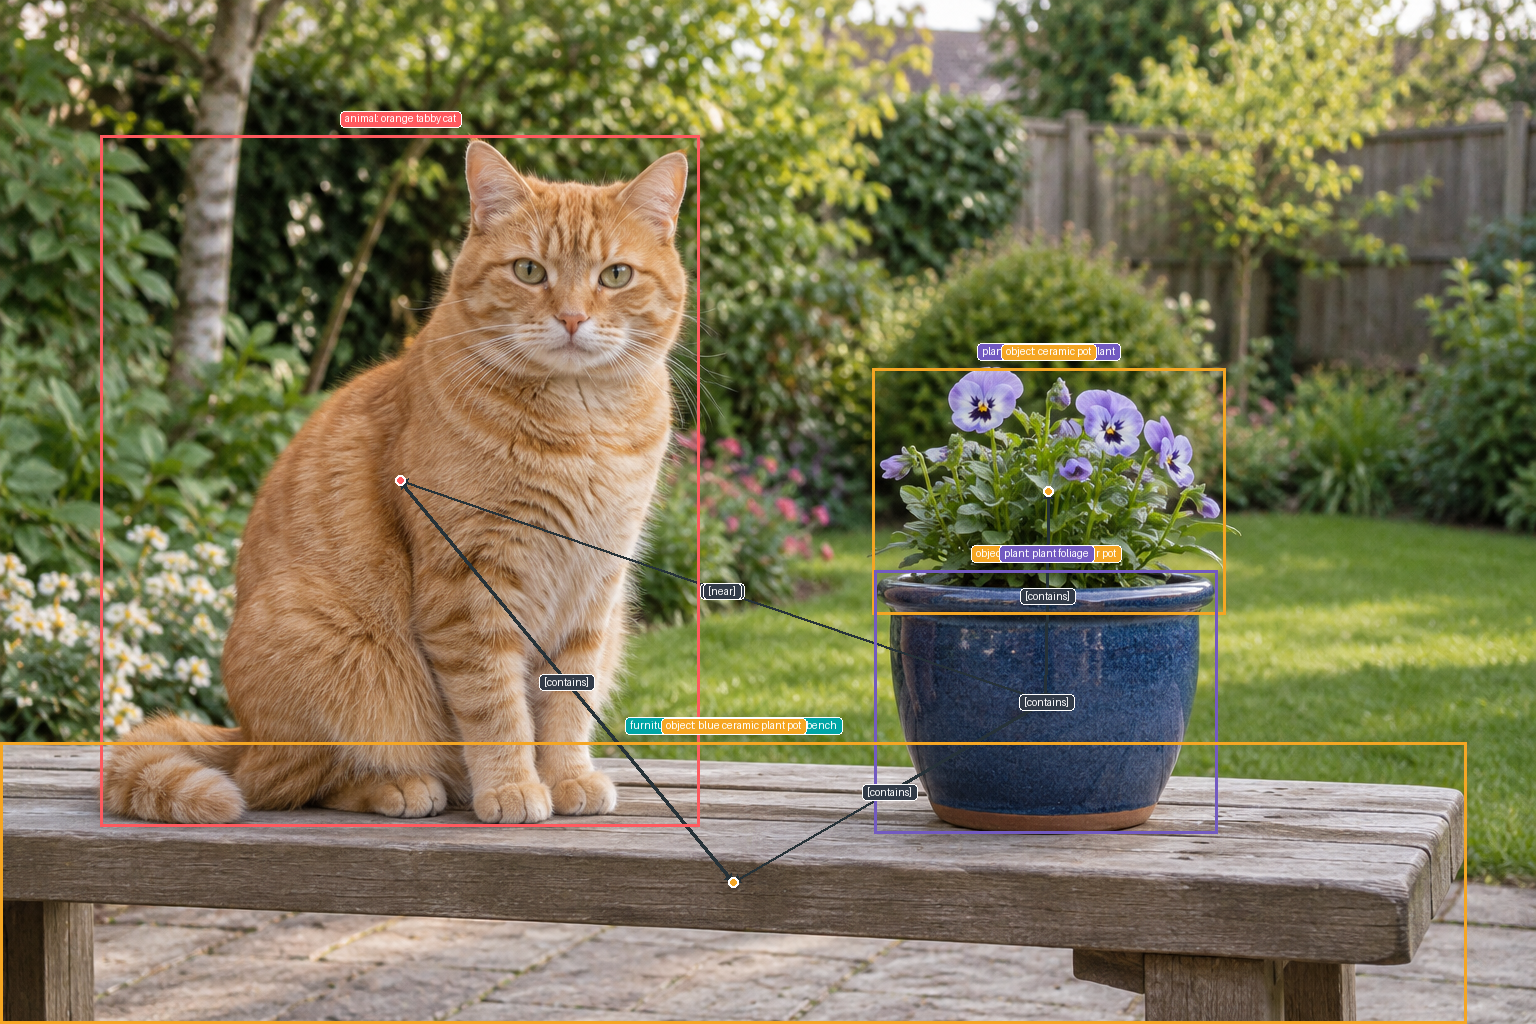

In [ ]:
display(graphicalizer.display_on_image(graph, image=image_path))

In [ ]:
display_graph(
    graph,
    mode='dynamic',
    exclude_nodes=scene_nodes,
    layout='force',
    show_relations_as_edges=True,
    show_source=True,
    max_width=34,
    width=1200,
    height=760,
    charge_strength=-10,
    link_distance=150,
    component_spacing=100,
    component_strength=0.3,
    parallel_edge_spacing=320,
)

## Inspect region crops and provenance

Each part records its source image, normalized bounding box, pixel bounding box, and saved crop path. Invalid or zero-area boxes are skipped and reported in `graph.graph['warnings']`.

image-e5adcf184a38:region:0:cat_1
Box: [0.065, 0.132, 0.456, 0.808] (normalized)
Pixels: [99, 135, 701, 828]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-e5adcf184a38/000-cat_1.png


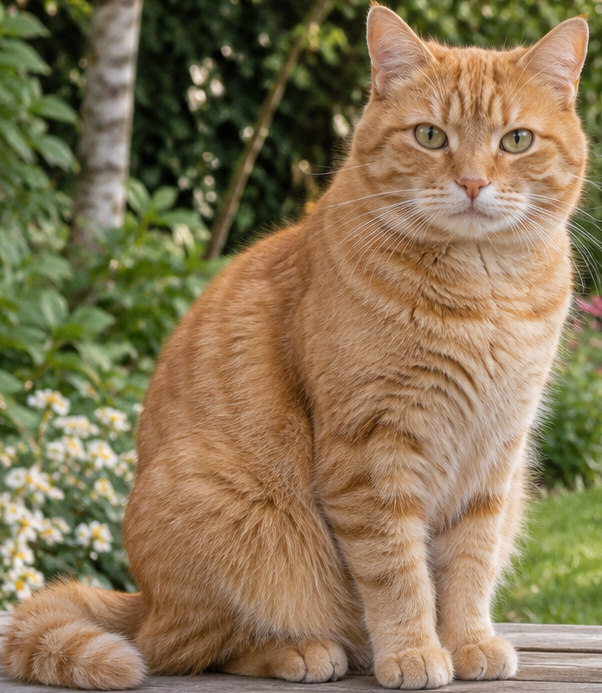

image-e5adcf184a38:region:1:potted_flower_1
Box: [0.568, 0.359, 0.798, 0.601] (normalized)
Pixels: [872, 367, 1226, 616]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-e5adcf184a38/001-potted_flower_1.png


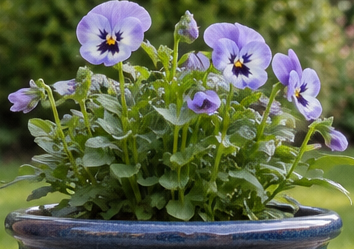

image-e5adcf184a38:region:2:flower_pot_1
Box: [0.569, 0.557, 0.793, 0.814] (normalized)
Pixels: [873, 570, 1219, 834]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-e5adcf184a38/002-flower_pot_1.png


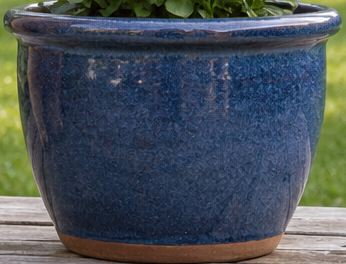

image-e5adcf184a38:region:3:bench_1
Box: [0.0, 0.725, 0.955, 1.0] (normalized)
Pixels: [0, 742, 1467, 1024]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-e5adcf184a38/003-bench_1.png


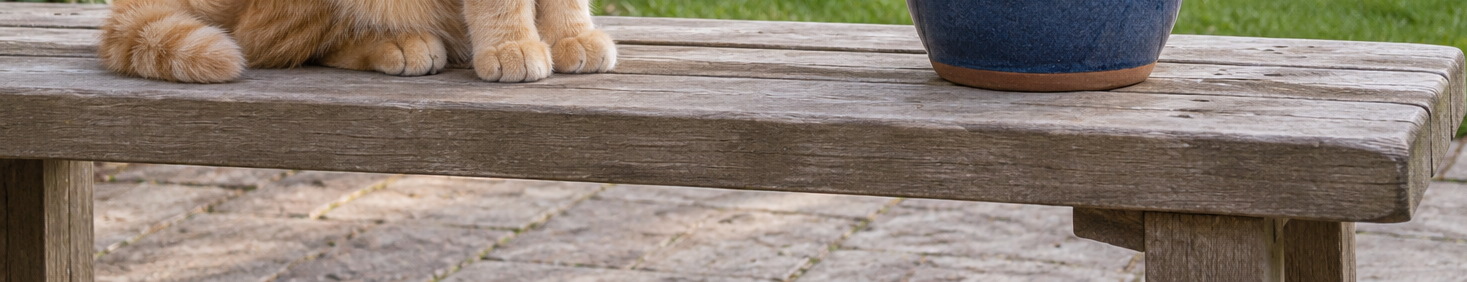

[]

In [ ]:
for part in graph.graph['parts']:
    print(part['part_id'])
    print(f"Box: {part['source_locator']['normalized_bbox']} (normalized)")
    print(f"Pixels: {part['source_locator']['pixel_bbox']}")
    print(f"Crop: {part['metadata']['crop_path']}")
    display(DisplayImage(filename=part['metadata']['crop_path'], width=360))

graph.graph['warnings']